# Dendrogramma e embedding

Collega l'**albero** dell'agglomerative ai **punti dell'embedding**: dice quali gruppi di soggetti vengono uniti, a quale distanza, e dove stanno nell'embedding.

Il dendrogramma da solo non lo dice: in basso mostra rami (con il numero di soggetti), non soggetti. Qui ogni ramo viene riportato sull'embedding con lo stesso colore.

Legge una run di tuning **già eseguita** e non rifà nessun tuning. Ricalcola solo l'albero (pochi secondi su un embedding 2D).

## Helper

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, to_tree
from sklearn.metrics import adjusted_rand_score

# Repo root isn't on sys.path when this notebook runs with cwd=notebooks/post-results_analysis/ -
# needed for the `from src...` imports below.
NOTEBOOK_REPO_ROOT = Path.cwd().resolve().parents[1]
if str(NOTEBOOK_REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_REPO_ROOT))

from src.analysis.clustering_tuning import compute_dendrogram_linkage, is_invalid_ward_metric_combo
from src.utils.artifacts import load_matrix

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)

MAX_LEAVES = 20  # tab20 ha 20 colori distinti

In [2]:
def read_tuning_config(run_dir: Path) -> dict:
    """Parses the JSON block embedded in a tuning run's config.md."""
    config_path = run_dir / "config.md"
    if not config_path.is_file():
        raise FileNotFoundError(f"no config.md in {run_dir}")
    text = config_path.read_text()
    if "```json" not in text:
        raise ValueError(f"{config_path} has no ```json config block")
    return json.loads(text.split("```json", 1)[1].split("```", 1)[0])


def load_run(run_dir: Path, linkage: str, metric: str, cut_k: int) -> tuple[np.ndarray, pd.DataFrame, np.ndarray]:
    """Embedding 2D su cui la run è stata calcolata, i suoi soggetti, e le etichette salvate per (cut_k, linkage, metric).
    Solleva se l'embedding non è 2D, se i soggetti non coincidono con quelli della run, o se la combinazione non c'è."""
    if not run_dir.is_dir():
        raise FileNotFoundError(f"run directory not found: {run_dir}")
    if is_invalid_ward_metric_combo({"linkage": linkage, "metric": metric}):
        raise ValueError("ward esiste solo con la metrica euclidean")
    config = read_tuning_config(run_dir)
    embedding, embedding_metadata, _ = load_matrix(NOTEBOOK_REPO_ROOT / config["input_path"])
    if embedding.shape[1] != 2:
        raise ValueError(f"l'embedding ha {embedding.shape[1]} componenti: qui servono 2 (per disegnarlo)")
    run_subjects = pd.read_csv(run_dir / "metadata.csv")
    if not embedding_metadata["subject_id"].equals(run_subjects["subject_id"]):
        raise ValueError("i soggetti dell'embedding non coincidono, nello stesso ordine, con quelli della run")
    saved = np.load(run_dir / "clusterings.npz")
    key = f"n_clusters={cut_k},linkage={linkage},metric={metric}"
    if key not in saved:
        raise KeyError(f"{key!r} non è in clusterings.npz")
    return embedding, run_subjects, saved[key]

In [3]:
def leaves_of_truncated_tree(Z: np.ndarray, last_p: int) -> tuple[dict, list[np.ndarray], np.ndarray]:
    """Le `last_p` foglie del dendrogramma troncato (ultime last_p-1 fusioni), da sinistra a destra, e i soggetti di
    ciascuna. Ritorna (layout scipy per disegnarlo, soggetti per foglia, indice di foglia di ogni soggetto).
    Solleva se le foglie non coprono ogni soggetto esattamente una volta."""
    if last_p > MAX_LEAVES:
        raise ValueError(f"LAST_P={last_p}: oltre {MAX_LEAVES} i colori si ripetono")
    n_subjects = Z.shape[0] + 1
    layout = dendrogram(Z, truncate_mode="lastp", p=last_p, no_plot=True)
    _root, nodes = to_tree(Z, rd=True)
    members = [np.array(nodes[leaf].pre_order()) for leaf in layout["leaves"]]
    leaf_of_subject = np.full(n_subjects, -1)
    for leaf_index, subjects in enumerate(members):
        if (leaf_of_subject[subjects] != -1).any():
            raise ValueError("un soggetto compare in due foglie")
        leaf_of_subject[subjects] = leaf_index
    if (leaf_of_subject == -1).any():
        raise ValueError("alcuni soggetti non stanno in nessuna foglia")
    return layout, members, leaf_of_subject


def cut_height(Z: np.ndarray, cut_k: int) -> float:
    """Altezza di un taglio orizzontale che dà cut_k cluster: a metà tra l'ultima fusione tenuta e la prima scartata."""
    return float((Z[-(cut_k - 1), 2] + Z[-cut_k, 2]) / 2)

In [4]:
def plot_tree_and_embedding(Z, layout, members, leaf_of_subject, embedding, cut_k, title) -> None:
    """A sinistra l'albero troncato, a destra l'embedding: ogni foglia ha lo stesso colore e la stessa sigla (L1, L2, ...)
    nei due pannelli. La linea rossa è il taglio a cut_k cluster."""
    colors = plt.get_cmap("tab20")
    fig, (ax_tree, ax_embedding) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})

    for xs, ys in zip(layout["icoord"], layout["dcoord"]):
        ax_tree.plot(xs, ys, color="0.35", linewidth=1)
    positions = [5 + 10 * i for i in range(len(members))]
    ax_tree.set_xticks(positions)
    ax_tree.set_xticklabels([f"L{i + 1}\n({len(m)})" for i, m in enumerate(members)], fontsize=8)
    for tick, i in zip(ax_tree.get_xticklabels(), range(len(members))):
        tick.set_bbox({"facecolor": colors(i), "edgecolor": "none", "alpha": 0.8, "pad": 2})
    height = cut_height(Z, cut_k)
    ax_tree.axhline(height, color="red", linestyle="--", linewidth=1)
    ax_tree.text(0.99, height, f" taglio k={cut_k}", color="red", va="bottom", ha="right",
                 transform=ax_tree.get_yaxis_transform(), fontsize=8)
    ax_tree.set_ylabel("distanza di fusione")
    ax_tree.set_xlabel("foglia (numero di soggetti)")
    ax_tree.set_title("Albero (ultime fusioni)")

    ax_embedding.scatter(embedding[:, 0], embedding[:, 1], c=[colors(l) for l in leaf_of_subject], s=4, linewidths=0)
    for i, subjects in enumerate(members):
        cx, cy = np.median(embedding[subjects], axis=0)
        ax_embedding.text(cx, cy, f"L{i + 1}", fontsize=9, fontweight="bold", ha="center", va="center",
                          bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.7, "pad": 1})
    ax_embedding.set_xlabel("dim 1")
    ax_embedding.set_ylabel("dim 2")
    ax_embedding.set_title("Embedding, colorato per foglia")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

In [5]:
def merge_steps(Z: np.ndarray, labels: np.ndarray) -> pd.DataFrame:
    """Le fusioni sopra il taglio, dalla più bassa alla più alta: quali cluster (le etichette `labels`) si uniscono a
    quale distanza. Ogni lato di una fusione sopra il taglio è fatto di cluster interi: solleva se non lo è."""
    n_subjects = Z.shape[0] + 1
    n_clusters = len(np.unique(labels))
    _root, nodes = to_tree(Z, rd=True)
    rows = []
    for step, row in enumerate(Z[-(n_clusters - 1):], start=1):
        sides = [set(labels[nodes[int(child)].pre_order()].tolist()) for child in row[:2]]
        if sides[0] & sides[1]:
            raise ValueError(f"la fusione {step} spezza un cluster: il taglio non coincide con le etichette")
        rows.append({
            "fusione": step,
            "distanza": round(float(row[2]), 2),
            "unisce": " + ".join("{" + ", ".join(map(str, sorted(side))) + "}" for side in sides),
            "soggetti": int(row[3]),
        })
    return pd.DataFrame(rows)

## 0. Scegli la run

`RUN_DIR` è la cartella della run di tuning; `LINKAGE` e `METRIC` sono la combinazione da guardare (ward funziona solo con euclidean).

`LAST_P` è quante foglie mostrare nell'albero (al massimo 20): più sono, più dettaglio c'è, ma più sigle da leggere. `CUT_K` è il numero di cluster del taglio e deve stare tra 2 e `LAST_P`.

In [6]:
RUN_DIR = NOTEBOOK_REPO_ROOT / "results/sdc/clustering/tuning/agglomerative/umap/16-10_s2.4-vol_m_euclidean_nc2"
LINKAGE = "ward"
METRIC = "euclidean"
LAST_P = 15
CUT_K = 3

if not 2 <= CUT_K <= LAST_P:
    raise ValueError(f"CUT_K={CUT_K} deve stare tra 2 e LAST_P={LAST_P}")

embedding, run_subjects, saved_labels = load_run(RUN_DIR, LINKAGE, METRIC, CUT_K)
Z = compute_dendrogram_linkage(embedding, {"linkage": LINKAGE, "metric": METRIC})
print(f"{len(embedding)} soggetti | embedding {embedding.shape[1]}D | albero: {Z.shape[0]} fusioni")

5845 soggetti | embedding 2D | albero: 5844 fusioni


### Controllo: l'albero ricalcolato è quello della run

L'albero non è salvato nella run, quindi lo ricalcoliamo. Per esserne sicuri, tagliamo l'albero a `CUT_K` cluster e lo confrontiamo con le etichette che la run aveva salvato per la stessa combinazione.

L'**ARI** (*adjusted Rand index*) misura quanto due divisioni degli stessi soggetti coincidono: 1 = identiche, 0 = quanto il caso. Qui deve essere esattamente 1, altrimenti il notebook si ferma.

In [7]:
cut_labels = fcluster(Z, CUT_K, "maxclust")
ari = adjusted_rand_score(saved_labels, cut_labels)
if ari != 1.0:
    raise ValueError(f"l'albero ricalcolato non riproduce le etichette salvate (ARI={ari:.4f})")
print(f"ARI tra taglio ricalcolato e etichette salvate: {ari:.1f}")

ARI tra taglio ricalcolato e etichette salvate: 1.0


## 1. Quali gruppi vengono uniti, e dove stanno nell'embedding

**Perché lo facciamo**

Il dendrogramma dice che due rami si uniscono a una certa distanza, ma non dove stanno quei soggetti. Qui ogni foglia dell'albero viene colorata anche sull'embedding.

**Cosa mostra**

- A sinistra l'albero. In basso ci sono le foglie `L1`, `L2`, ...: ognuna è un gruppo di soggetti già formato, e tra parentesi c'è quanti sono.

- A destra l'embedding, con gli stessi colori e le stesse sigle.

- La linea rossa è il taglio a `CUT_K` cluster: ogni linea verticale che attraversa è un cluster.

- L'ordine delle foglie sull'asse x è solo di disegno. Contano i rami che si uniscono, non la distanza orizzontale.

**Come leggerlo**

- Foglie che si uniscono presto (in basso) sono vicine nello spazio su cui è calcolato l'albero. Controlla se sono vicine anche nell'embedding.

- Foglie che si uniscono solo in cima, a distanza molto più alta, sono davvero separate: ci aspettiamo zone distinte dell'embedding.

**Attenzione**

Per costruzione, un albero euclideo su un embedding 2D raggruppa punti vicini nel piano. Che l'embedding mostri gruppi contigui è quindi atteso, non una conferma indipendente.

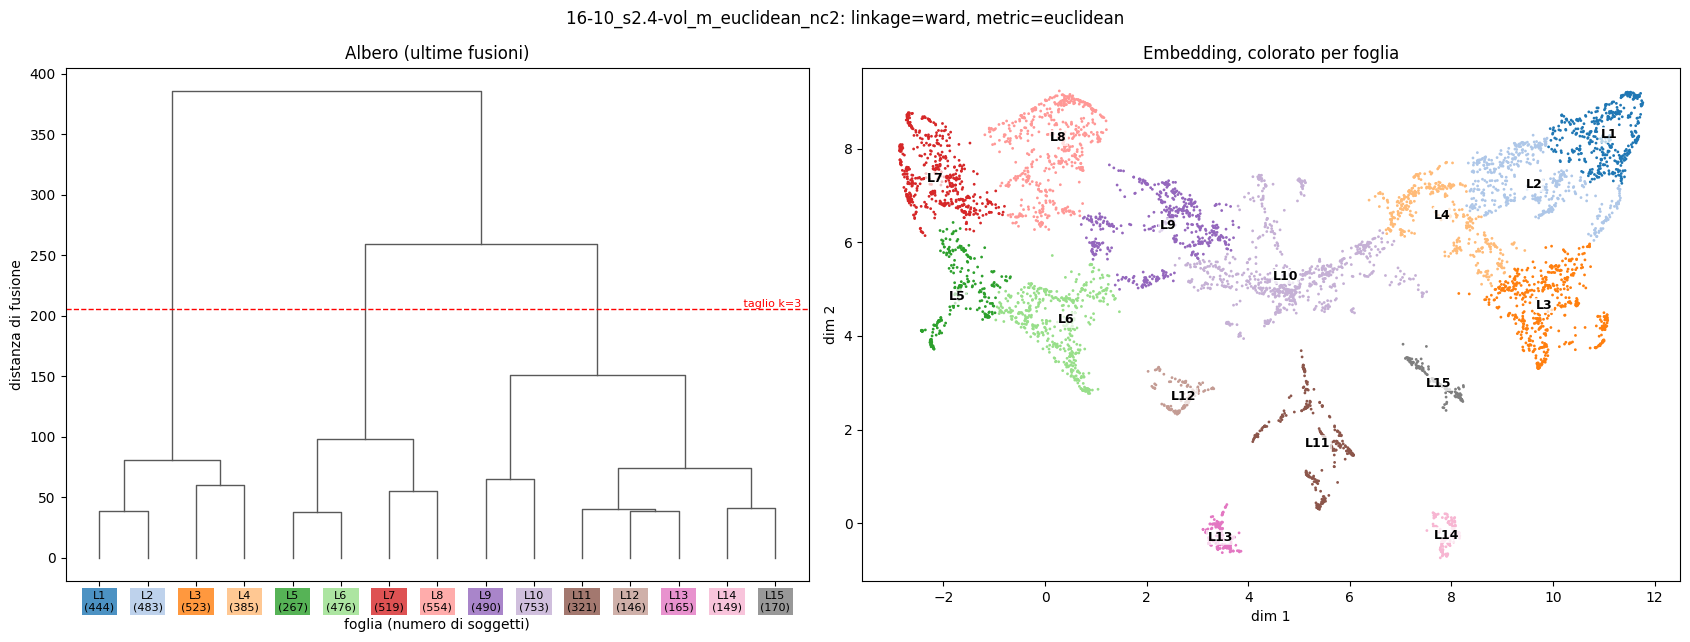

In [8]:
layout, members, leaf_of_subject = leaves_of_truncated_tree(Z, LAST_P)
plot_tree_and_embedding(
    Z, layout, members, leaf_of_subject, embedding, CUT_K,
    f"{RUN_DIR.name}: linkage={LINKAGE}, metric={METRIC}",
)

## 2. Cosa viene unito a ogni passo

**Perché lo facciamo**

Rispondere alla domanda "quali cluster si raggruppano insieme?" con una tabella, usando le stesse etichette che compaiono nei grafici della run.

**Cosa mostra**

- Le fusioni sopra il taglio a `CUT_K`, dalla più bassa alla più alta.

- `distanza` è l'altezza della fusione nell'albero. `unisce` elenca i cluster (con la loro etichetta) che finiscono insieme. `soggetti` è la dimensione del gruppo risultante.

**Come leggerlo**

- Il cluster che si unisce solo all'ultima fusione, a distanza molto più alta delle altre, è quello più separato.

- La differenza tra la distanza di una fusione e quella della successiva dice quanto il passaggio da k a k-1 cluster costa: un salto grande vuol dire che quei cluster erano ben distinti.

In [9]:
merge_steps(Z, saved_labels)

,fusione,distanza,unisce,soggetti
0,1,259.67,{2} + {0},4010
1,2,385.98,"{1} + {0, 2}",5845


## 3. Come le foglie si distribuiscono nei cluster

**Perché lo facciamo**

Collegare le sigle `L1`, `L2`, ... dell'albero ai cluster del taglio.

**Cosa mostra**

Una tabella con una riga per foglia e una colonna per cluster: ogni cella conta i soggetti della foglia che stanno in quel cluster.

**Come leggerlo**

Ogni foglia deve cadere in **un solo** cluster (una sola colonna diversa da zero): se la linea rossa passa sopra le foglie, un ramo non può essere spezzato dal taglio. Se non è così, `LAST_P` è troppo piccolo per `CUT_K`.

In [10]:
leaf_table = pd.crosstab(
    pd.Series([f"L{i + 1}" for i in leaf_of_subject], name="foglia"),
    pd.Series(saved_labels, name="cluster"),
)
leaf_table = leaf_table.loc[[f"L{i + 1}" for i in range(LAST_P)]]
if ((leaf_table > 0).sum(axis=1) != 1).any():
    raise ValueError("una foglia è spezzata dal taglio: aumenta LAST_P o abbassa CUT_K")
leaf_table

cluster,0,1,2
foglia,,,
L1,0,444,0
L2,0,483,0
L3,0,523,0
L4,0,385,0
L5,0,0,267
L6,0,0,476
L7,0,0,519
L8,0,0,554
L9,490,0,0


## 4. Chi sono i soggetti dei cluster

**Perché lo facciamo**

Dare un significato clinico ai cluster del taglio, guardando di quali soggetti sono fatti.

**Cosa mostra**

Per ogni cluster, il numero di soggetti e la loro composizione per lato della lesione (`lesion_side`) e per dataset, in percentuale di riga: ogni riga somma a 100.

I dati vengono da `assets/metadata/participants.csv`. Il lato è mancante per pochi soggetti: compaiono nella colonna `mancante`.

**Come leggerlo**

- Una percentuale molto più alta in un cluster che nel totale (ultima riga) indica che quel gruppo è fatto prevalentemente di quel lato o di quel dataset.

- È una descrizione, non un test: non dice se la differenza è significativa.

In [11]:
participants = pd.read_csv(NOTEBOOK_REPO_ROOT / "assets/metadata/participants.csv", usecols=["subject_id", "dataset", "lesion_side"])
missing = set(run_subjects["subject_id"]) - set(participants["subject_id"])
if missing:
    raise ValueError(f"{len(missing)} soggetti della run non sono in participants.csv, per esempio {sorted(missing)[:3]}")
described = run_subjects[["subject_id"]].merge(participants, on="subject_id", how="left", validate="one_to_one")
described["lesion_side"] = described["lesion_side"].fillna("mancante")
described["cluster"] = saved_labels


def composition(column: str) -> pd.DataFrame:
    counts = pd.crosstab(described["cluster"], described[column])
    share = (counts.div(counts.sum(axis=1), axis=0) * 100).round(1)
    share.loc["totale"] = (counts.sum() / counts.values.sum() * 100).round(1)
    share.insert(0, "soggetti", list(counts.sum(axis=1)) + [counts.values.sum()])
    return share


composition("lesion_side")

lesion_side,soggetti,both,left,mancante,right
cluster,,,,,
0,2194,2.2,59.5,0.1,38.1
1,1835,1.0,0.4,0.0,98.5
2,1816,1.1,98.5,0.0,0.4
totale,5845,1.5,53.1,0.1,45.4


In [12]:
composition("dataset")

dataset,soggetti,UCL-UK/UCLStrokeData,UKE/SFB936_ses01,UKE/WAKEUP_acute,UKLFR/stroke_UKLFR,UNIPD/NEMESIS_T0,UNIPD/PASPORT,UNIPD/PSP,UNIPD/WashU
cluster,,,,,,,,,
0,2194,79.5,0.6,7.3,5.1,1.1,0.5,2.7,3.2
1,1835,68.7,1.4,7.4,13.8,1.0,1.5,2.6,3.5
2,1816,61.4,0.9,8.4,18.6,1.8,2.3,3.4,3.3
totale,5845,70.5,1.0,7.7,12.0,1.3,1.4,2.9,3.3


## 5. Il taglio sull'embedding

**Perché lo facciamo**

Vedere i cluster del taglio con le etichette della tabella della sezione 2, senza la suddivisione in foglie.

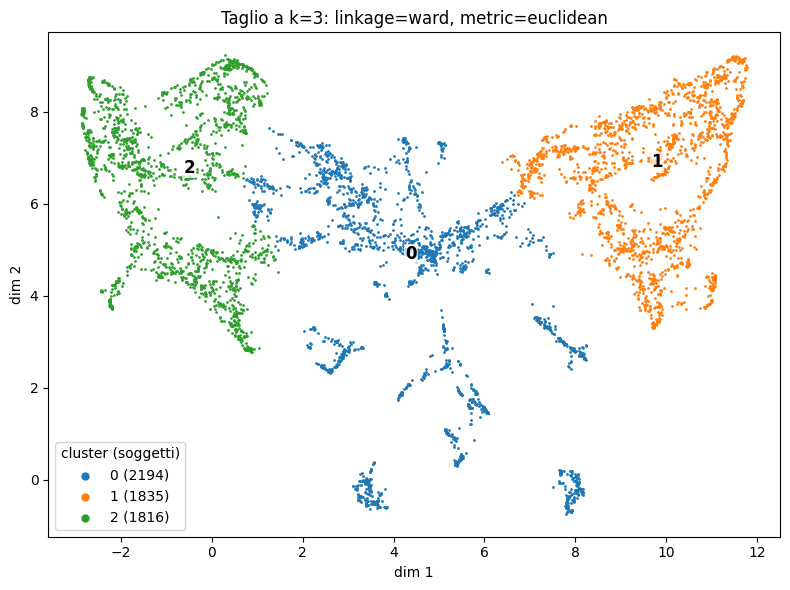

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.get_cmap("tab10")
for cluster in np.unique(saved_labels):
    points = embedding[saved_labels == cluster]
    ax.scatter(points[:, 0], points[:, 1], s=4, linewidths=0, color=colors(int(cluster) % 10), label=f"{cluster} ({len(points)})")
    cx, cy = np.median(points, axis=0)
    ax.text(cx, cy, str(cluster), fontsize=12, fontweight="bold", ha="center", va="center",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.7, "pad": 1})
ax.legend(title="cluster (soggetti)", markerscale=3)
ax.set_xlabel("dim 1")
ax.set_ylabel("dim 2")
ax.set_title(f"Taglio a k={CUT_K}: linkage={LINKAGE}, metric={METRIC}")
fig.tight_layout()
plt.show()